# Визначення тональності текстових відгуків (positive / negative)

**Задача.** Бінарна класифікація: за текстом відгуку $x$ передбачити $y \in \{0 = \text{negative},\ 1 = \text{positive}\}$.
Кожна модель повертає оцінку $p(y=1 \mid x)$, клас визначаємо за порогом $\tau = 0.5$ (класи збалансовані).

**Дані.** Rotten Tomatoes (Pang & Lee, 2005): 10 662 речення-рецензії на фільми, офіційний поділ
train 8530 / validation 1066 / test 1066.

**Моделі** — від простої до складної:

| # | Модель | Що перевіряємо |
|---|---|---|
| 1 | TF-IDF + логістична регресія | сильний класичний baseline (мішок слів і біграм) |
| 2 | FastText-style (середнє embeddings) | щільні навчувані представлення слів, **без** порядку слів |
| 3 | BiGRU | рекурентна модель: порядок слів і контекст з обох боків |
| 4 | DistilBERT (fine-tuning) | передтренований трансформер |

**Дослідницькі питання.**
1. Наскільки сильний TF-IDF baseline?
2. Чи дає врахування порядку слів (BiGRU) перевагу над усередненням embeddings (FastText)?
3. Чи виправдовує DistilBERT свою обчислювальну вартість?
4. Як якість залежить від обсягу навчальних даних (вибіркова ефективність)?
5. Які відгуки складні для всіх моделей?

**Експериментальний протокол** (лекція «Вибірки та метрики якості»):
- test не використовується ні для preprocessing, ні для вибору моделі; словник і TF-IDF навчаються **лише на train**;
- кожна конфігурація гіперпараметрів навчається з **3 seed**; обираємо конфігурацію з найбільшим **середнім val F1**;
- для обраної конфігурації звітуємо test-метрики як **mean ± std** за seed та бутстреп 95% довірчий інтервал;
- метрики: accuracy, precision, recall, F1, PR-крива та average precision (AP), confusion matrix, час навчання та інференсу.

## 1. Імпорти, конфігурація, відтворюваність

In [1]:
!pip install -q "transformers>=4.41" datasets accelerate scikit-learn pandas matplotlib seaborn

In [2]:
import copy, itertools, json, math, re, shutil, sys, time
from collections import Counter
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

import datasets, sklearn, transformers
from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_recall_fscore_support)
from transformers import (AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding,
                          Trainer, TrainingArguments, set_seed)

sns.set_style("whitegrid")
datasets.disable_progress_bars()
transformers.logging.set_verbosity_error()

Уся конфігурація експериментів — в одному словнику `CFG`. Для кожної моделі: `fixed` — фіксовані параметри,
`grid` — сітка, яку перебираємо. Конфігурація та версії бібліотек зберігаються у `configs/`.

In [3]:
CFG = {
    "seeds": [1, 2, 42],                   # кожна конфігурація навчається з 3 seed → mean ± std
    "fracs": [0.05, 0.1, 0.25, 0.5, 1.0],  # частки train для аналізу вибіркової ефективності
    "threshold": 0.5,                      # поріг класифікації: класи збалансовані
    "rnn_data": {"min_freq": 2, "max_len": 64, "batch_size": 64},
    "tfidf": {"fixed": {"ngram_range": [1, 2], "min_df": 2},
              "grid": {"C": [0.1, 0.3, 1, 3, 10]}},
    "fasttext": {"fixed": {"dropout": 0.3, "weight_decay": 1e-4, "epochs": 20, "patience": 3, "clip": None},
                 "grid": {"emb_dim": [100, 300], "lr": [1e-3, 5e-3]}},
    "bigru": {"fixed": {"emb_dim": 128, "lr": 1e-3, "weight_decay": 1e-4, "epochs": 15, "patience": 3, "clip": 1.0},
              "grid": {"hidden": [64, 128], "dropout": [0.2, 0.5]}},
    "distilbert": {"fixed": {"checkpoint": "distilbert-base-uncased", "batch": 32, "epochs": 3, "max_len": 128,
                             "weight_decay": 0.01, "warmup_ratio": 0.1},
                   "grid": {"lr": [1e-5, 3e-5, 1e-4]}},
}
MODELS = ["tfidf", "fasttext", "bigru", "distilbert"]
NAMES = {"tfidf": "TF-IDF + LogReg", "fasttext": "FastText-style", "bigru": "BiGRU", "distilbert": "DistilBERT"}
SEEDS, FRACS, THR = CFG["seeds"], CFG["fracs"], CFG["threshold"]

RESULTS, CONFIGS = Path("results"), Path("configs")
RUNS_DIR, FIG_DIR = RESULTS / "runs", RESULTS / "figures"
for d in (RUNS_DIR, FIG_DIR, CONFIGS):
    d.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
N_GPU = max(1, torch.cuda.device_count())  # доступні GPU; усі моделі навчаються на одній (див. розділ 7)
torch.backends.cudnn.deterministic, torch.backends.cudnn.benchmark = True, False

env = {"python": sys.version.split()[0], "torch": torch.__version__, "transformers": transformers.__version__,
       "datasets": datasets.__version__, "scikit-learn": sklearn.__version__,
       "device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu", "n_gpu": N_GPU}
(CONFIGS / "config.json").write_text(json.dumps(CFG, indent=2))
(CONFIGS / "environment.json").write_text(json.dumps(env, indent=2))
print(json.dumps(env, indent=2))

{
  "python": "3.13.16",
  "torch": "2.11.0+cu130",
  "transformers": "5.20.2",
  "datasets": "4.8.5",
  "scikit-learn": "1.6.1",
  "device": "Tesla T4",
  "n_gpu": 2
}


## 2. Дані та EDA

Датасет уже приведений до нижнього регістру й токенізований (слова та пунктуація розділені пробілами).
Завантажуємо офіційний поділ і перевіряємо баланс класів.

In [4]:
ds = load_dataset("cornell-movie-review-data/rotten_tomatoes")
SPLITS = ["train", "validation", "test"]

counts = pd.DataFrame({s: pd.Series(ds[s]["label"]).value_counts().sort_index() for s in SPLITS}).T
counts.columns = ["negative (0)", "positive (1)"]
counts["total"] = counts.sum(axis=1)
print(counts)

README.md:   0%|          | 0.00/7.46k [00:00<?, ?B/s]

train.parquet: reconstructing file:   0%|          |  0.00B /  699kB            

train.parquet: downloading bytes:           |  0.00B            

validation.parquet: reconstructing file:   0%|          |  0.00B / 90.0kB            

validation.parquet: downloading bytes:           |  0.00B            

test.parquet: reconstructing file:   0%|          |  0.00B / 92.2kB            

test.parquet: downloading bytes:           |  0.00B            

            negative (0)  positive (1)  total
train               4265          4265   8530
validation           533           533   1066
test                 533           533   1066


### Контроль якості: дублікати та витік даних

Дублікат тексту з validation/test у train — це витік даних (data leakage): модель «складає іспит за завданням,
яке вже бачила». Такі приклади видаляємо **з train**, а validation і test лишаємо без змін.

In [5]:
train_texts = ds["train"]["text"]
eval_texts = set(ds["validation"]["text"]) | set(ds["test"]["text"])
labels_per_text = pd.DataFrame(ds["train"][:]).groupby("text")["label"].nunique()

print("Дублікати всередині train:          ", len(train_texts) - len(set(train_texts)))
print("Тексти з різними мітками в train:   ", int((labels_per_text > 1).sum()))
print("Спільні тексти validation і test:   ", len(set(ds["validation"]["text"]) & set(ds["test"]["text"])))
leak = sum(t in eval_texts for t in train_texts)
print("Тексти train, що є у validation/test:", leak)

if leak:
    ds["train"] = ds["train"].filter(lambda e: e["text"] not in eval_texts)
    print("→ видалено з train; новий розмір train:", len(ds["train"]))

Дублікати всередині train:           0
Тексти з різними мітками в train:    0
Спільні тексти validation і test:    0
Тексти train, що є у validation/test: 0


### Довжина відгуків

Довжина потрібна, щоб обґрунтувати `max_len`: для BiGRU/FastText — у словах, для DistilBERT — у subword-токенах.
Аналізуємо лише train, щоб рішення щодо preprocessing не залежали від test.

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Середня довжина за класом:
        n_words  n_tokens
label                   
0         20.9      27.5
1         21.0      27.3 

Квантилі довжини:
           0.50  0.95  0.99  1.00
n_words   20.0  37.0  45.0  59.0
n_tokens  27.0  47.0  56.0  78.0 

Обрізаються для BiGRU/FastText (> 64 слів):    0.00%
Обрізаються для DistilBERT   (> 128 токенів): 0.00%


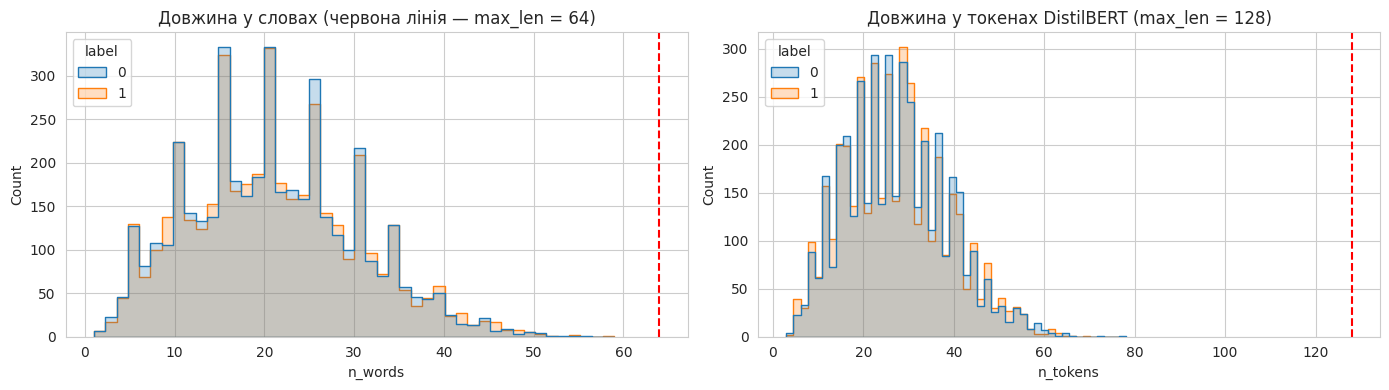

In [6]:
tok = AutoTokenizer.from_pretrained(CFG["distilbert"]["fixed"]["checkpoint"])
RNN_LEN, BERT_LEN = CFG["rnn_data"]["max_len"], CFG["distilbert"]["fixed"]["max_len"]

eda = ds["train"].to_pandas()
eda["n_words"] = eda.text.str.split().str.len()
eda["n_tokens"] = [len(ids) for ids in tok(eda.text.tolist())["input_ids"]]

print("Середня довжина за класом:\n", eda.groupby("label")[["n_words", "n_tokens"]].mean().round(1), "\n")
print("Квантилі довжини:\n", eda[["n_words", "n_tokens"]].quantile([0.5, 0.95, 0.99, 1.0]).T, "\n")
print(f"Обрізаються для BiGRU/FastText (> {RNN_LEN} слів):    {(eda.n_words > RNN_LEN).mean():.2%}")
print(f"Обрізаються для DistilBERT   (> {BERT_LEN} токенів): {(eda.n_tokens > BERT_LEN).mean():.2%}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=eda, x="n_words", hue="label", element="step", ax=ax[0])
ax[0].axvline(RNN_LEN, color="red", ls="--")
ax[0].set_title(f"Довжина у словах (червона лінія — max_len = {RNN_LEN})")
sns.histplot(data=eda, x="n_tokens", hue="label", element="step", ax=ax[1])
ax[1].axvline(BERT_LEN, color="red", ls="--")
ax[1].set_title(f"Довжина у токенах DistilBERT (max_len = {BERT_LEN})")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_lengths.png", dpi=150)
plt.show()

In [7]:
for label, name in [(1, "POSITIVE"), (0, "NEGATIVE")]:
    print(f"--- {name}")
    for t in eda[eda.label == label].text.sample(3, random_state=0):
        print("   ", t)

--- POSITIVE
    good , solid storytelling .
    it's a satisfying summer blockbuster and worth a look .
    what lee does so marvelously compelling is present brown as a catalyst for the struggle of black manhood in restrictive and chaotic america . . . sketchy but nevertheless gripping portrait of jim brown , a celebrated wonder in the spotlight
--- NEGATIVE
    la cinta comienza intentando ser un drama , rápidamente se transforma en una comedia y termina por ser una parodia absolutamente predecible
    there ought to be a directing license , so that ed burns can have his revoked .
    [newton]wanders through charlie completely unaware she needs to show some presence and star quality .


> **Спостереження (EDA).**
> - Класи ідеально збалансовані в усіх частинах: 4265 / 4265 у train, 533 / 533 у validation і test. Тому accuracy —
>   інформативна метрика, а поріг $\tau = 0.5$ природний.
> - Дублікатів, суперечливих міток і перетинів між train / validation / test немає → витоку даних немає,
>   офіційний поділ використовується без змін.
> - Відгуки короткі: медіана 20 слів (27 токенів DistilBERT), максимум 59 слів / 78 токенів. Отже `max_len` = 64 слова
>   і 128 токенів не обрізають жодного тексту.
> - Середня довжина однакова для обох класів (≈ 21 слово), тож довжина не є «підказкою» для класифікатора.
> - Серед прикладів трапляються тексти не англійською (іспанська рецензія в класі negative) — невеликий шум у даних.

## 3. Спільні хелпери: метрики, сітки, логування прогонів

Кожен прогін (модель × конфігурація × seed × частка train) повертає однаковий запис і зберігає JSON
у `results/runs/` (конфігурація, метрики, історія навчання) — це лог для відтворюваності.

In [8]:
X = {s: np.array(ds[s]["text"], dtype=object) for s in SPLITS}
y = {s: np.array(ds[s]["label"]) for s in SPLITS}
N_TRAIN = len(y["train"])
runs, BEST = [], {}  # усі прогони; обрана за validation конфігурація кожної моделі
HEAVY = ["hp", "history", "test_scores"]


def to_pred(scores):
    return (scores >= THR).astype(int)


def metrics(y_true, scores):
    pred = to_pred(scores)
    p, r, f1, _ = precision_recall_fscore_support(y_true, pred, average="binary", zero_division=0)
    return {"acc": accuracy_score(y_true, pred), "precision": p, "recall": r, "f1": f1,
            "ap": average_precision_score(y_true, scores)}  # AP рахується за неперервними оцінками


def bootstrap_f1(y_true, pred_a, pred_b=None, n=1000, seed=0):
    # 95% бутстреп-інтервал для test F1 або для різниці F1 двох моделей на тих самих прикладах
    rng = np.random.RandomState(seed)
    stats = []
    for idx in rng.randint(0, len(y_true), (n, len(y_true))):
        s = f1_score(y_true[idx], pred_a[idx])
        if pred_b is not None:
            s -= f1_score(y_true[idx], pred_b[idx])
        stats.append(s)
    return np.percentile(stats, [2.5, 97.5])


def subset_idx(frac, seed):
    # однакова підвибірка train для всіх моделей при тих самих (frac, seed)
    return np.random.RandomState(seed).permutation(N_TRAIN)[: int(N_TRAIN * frac)]


def grid_configs(model):
    c = CFG[model]
    return [{**c["fixed"], **dict(zip(c["grid"], vals))} for vals in itertools.product(*c["grid"].values())]


def config_label(model, hp):
    return " ".join(f"{k}={hp[k]}" for k in CFG[model]["grid"])


def make_record(model, hp, seed, frac, val_scores, test_scores, history, train_time, infer_time, n_params):
    label = config_label(model, hp)
    name = f"{model}_{label.replace(' ', '_')}_s{seed}_f{frac}"
    rec = {"model": model, "config": label, "seed": seed, "frac": frac, "n_train": int(N_TRAIN * frac),
           "val_f1": f1_score(y["validation"], to_pred(val_scores)),
           **{f"test_{k}": v for k, v in metrics(y["test"], test_scores).items()},
           "epochs_run": len(history.get("val_f1", [])), "train_time": train_time,
           "infer_time": infer_time, "n_params": n_params}
    (RUNS_DIR / f"{name}.json").write_text(json.dumps({**rec, "hp": hp, "history": history}, indent=2, default=float))
    print(f"{name:<60} val F1 = {rec['val_f1']:.4f}   ({train_time:.1f} s)")
    return {**rec, "hp": hp, "history": history, "test_scores": test_scores}


def runs_df():
    return pd.DataFrame([{k: v for k, v in r.items() if k not in HEAVY} for r in runs])


def sweep(model, run_fn):
    # сітка × seeds на повному train; вибір конфігурації — лише за середнім val F1
    runs[:] = [r for r in runs if r["model"] != model]  # безпечний повторний запуск клітинки
    for hp in grid_configs(model):
        for seed in SEEDS:
            runs.append(run_fn(hp, seed))
    df = runs_df()
    summary = df[df.model == model].groupby("config", sort=False)["val_f1"].agg(["mean", "std"])
    best = summary["mean"].idxmax()
    BEST[model] = next(hp for hp in grid_configs(model) if config_label(model, hp) == best)
    (CONFIGS / "best_configs.json").write_text(json.dumps(BEST, indent=2))
    print("\nval F1 за конфігураціями (3 seed):\n", summary.round(4), f"\n→ обрано: {best}")


def runs_of(model, seed=SEEDS[0]):
    return [r for r in runs if r["model"] == model and r["frac"] == 1 and r["seed"] == seed]


def best_run(model, seed=SEEDS[0]):
    return next(r for r in runs_of(model, seed) if r["config"] == config_label(model, BEST[model]))


def is_best(df):
    return df.config == df.model.map(lambda m: config_label(m, BEST[m]))

## 4. Модель 1: TF-IDF + логістична регресія

Документ → розріджений вектор TF-IDF уніграм і біграм (`sublinear_tf` — логарифмічна частота) → логістична регресія.
TF-IDF навчається лише на train. Логістична регресія дає ймовірність $p(y=1 \mid x)$, тому PR-крива й поріг
працюють так само, як для нейромереж. Підбираємо коефіцієнт регуляризації `C`
(менше `C` — сильніша L2-регуляризація). Модель детермінована, тож std за seed на повному train дорівнює 0.

In [9]:
def run_tfidf(hp, seed, frac=1.0):
    idx = subset_idx(frac, seed)
    start = time.time()
    vec = TfidfVectorizer(ngram_range=tuple(hp["ngram_range"]), min_df=hp["min_df"], sublinear_tf=True)
    clf = LogisticRegression(C=hp["C"], max_iter=1000).fit(vec.fit_transform(X["train"][idx]), y["train"][idx])
    train_time = time.time() - start

    proba = lambda split: clf.predict_proba(vec.transform(X[split]))[:, 1]  # p(y=1 | x)
    val_scores = proba("validation")
    start = time.time()
    test_scores = proba("test")
    infer_time = time.time() - start
    return make_record("tfidf", hp, seed, frac, val_scores, test_scores, {}, train_time, infer_time, clf.coef_.size + 1)


sweep("tfidf", run_tfidf)

tfidf_C=0.1_s1_f1.0                                          val F1 = 0.7309   (0.5 s)
tfidf_C=0.1_s2_f1.0                                          val F1 = 0.7309   (0.4 s)
tfidf_C=0.1_s42_f1.0                                         val F1 = 0.7309   (0.5 s)
tfidf_C=0.3_s1_f1.0                                          val F1 = 0.7391   (0.5 s)
tfidf_C=0.3_s2_f1.0                                          val F1 = 0.7391   (0.5 s)
tfidf_C=0.3_s42_f1.0                                         val F1 = 0.7391   (0.5 s)
tfidf_C=1_s1_f1.0                                            val F1 = 0.7516   (0.5 s)
tfidf_C=1_s2_f1.0                                            val F1 = 0.7516   (0.7 s)
tfidf_C=1_s42_f1.0                                           val F1 = 0.7516   (0.7 s)
tfidf_C=3_s1_f1.0                                            val F1 = 0.7491   (0.6 s)
tfidf_C=3_s2_f1.0                                            val F1 = 0.7491   (0.9 s)
tfidf_C=3_s42_f1.0                         

## 5. Підготовка даних для нейромереж, що навчаються з нуля

- **Словник** будується лише з train; слова з частотою < `min_freq` → `<unk>`, доповнення → `<pad>` (індекс 0).
- **Обрізання** до `max_len` = 64 слів — за EDA найдовший відгук має 59 слів, тож нічого не обрізається.
- **Padding у батчі**: послідовності доповнюються до найдовшої в батчі; справжні довжини передаються моделі,
  щоб PAD-позиції не впливали на результат (лекція RNN, §17).

In [10]:
MIN_FREQ, BATCH = CFG["rnn_data"]["min_freq"], CFG["rnn_data"]["batch_size"]
PAD, UNK = 0, 1

counter = Counter(w for t in X["train"] for w in t.split())  # лише train!
itos = ["<pad>", "<unk>"] + [w for w, c in counter.most_common() if c >= MIN_FREQ]
stoi = {w: i for i, w in enumerate(itos)}


def encode(text):
    return [stoi.get(w, UNK) for w in text.split()][:RNN_LEN] or [UNK]


encoded = {s: [encode(t) for t in X[s]] for s in SPLITS}
print(f"Розмір словника: {len(itos):,} (слова з частотою ≥ {MIN_FREQ} у train)")
for s in ("validation", "test"):
    tokens = [i for seq in encoded[s] for i in seq]
    print(f"Частка <unk> у {s}: {np.mean(np.array(tokens) == UNK):.2%}")


def collate(batch):
    ids, labels = zip(*batch)
    lengths = torch.tensor([len(x) for x in ids])
    x = nn.utils.rnn.pad_sequence([torch.tensor(x) for x in ids], batch_first=True, padding_value=PAD)
    return x, lengths, torch.tensor(labels)


def make_loader(split, idx=None, shuffle=False, seed=0):
    idx = range(len(y[split])) if idx is None else idx
    data = [(encoded[split][i], int(y[split][i])) for i in idx]
    return DataLoader(data, batch_size=BATCH, shuffle=shuffle, collate_fn=collate,
                      generator=torch.Generator().manual_seed(seed))


val_loader, test_loader = make_loader("validation"), make_loader("test")
x, lengths, labels = next(iter(val_loader))
print("Batch:", tuple(x.shape), "| довжини перших 8:", lengths[:8].tolist())

Розмір словника: 8,981 (слова з частотою ≥ 2 у train)
Частка <unk> у validation: 9.28%
Частка <unk> у test: 8.88%
Batch: (64, 50) | довжини перших 8: [18, 10, 20, 21, 8, 24, 10, 7]


## 6. Моделі 2–3: FastText-style та BiGRU

**FastText-style** — документ представляється середнім embeddings його слів (PAD не враховується):

$$h = \frac{1}{N}\sum_{i=1}^{N} e_{w_i}, \qquad \hat{y} = \mathrm{softmax}\big(W\,\mathrm{dropout}(h) + b\big).$$

На відміну від оригінального fastText (Joulin et al., 2017), n-грамних ознак немає: модель — чистий «мішок embeddings».
Тому порівняння з BiGRU показує саме внесок **порядку слів**.

**BiGRU** — задача many-to-one (лекція RNN, §1.1). Прямий GRU читає речення зліва направо, зворотний — справа наліво;
класифікатор отримує конкатенацію фінальних станів $[\overrightarrow{h}_T;\ \overleftarrow{h}_1]$.
GRU замість простої RNN, бо gates (update $z_t$, reset $r_t$) пом'якшують затухання градієнта (лекція RNN, §12).
`pack_padded_sequence` гарантує, що GRU не обробляє PAD-токени.

**Навчання** (у стилі `train_model` з прикладу MNIST): AdamW (decoupled weight decay, лекція з оптимізації, §10.2),
gradient clipping за нормою для BiGRU (§11) з логуванням норми градієнта та частки обрізаних кроків (§19),
рання зупинка за val F1 і відновлення найкращого чекпойнта.

In [11]:
class FastText(nn.Module):

    def __init__(self, vocab_size, emb_dim, dropout):
        super().__init__()
        # EmbeddingBag(mode="mean") усереднює embeddings, padding_idx виключається з середнього
        self.embedding = nn.EmbeddingBag(vocab_size, emb_dim, mode="mean", padding_idx=PAD)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(emb_dim, 2)

    def forward(self, x, lengths):
        h = self.embedding(x)                      # (B, emb_dim)
        return self.classifier(self.dropout(h))    # (B, 2) — логіти


class BiGRU(nn.Module):

    def __init__(self, vocab_size, emb_dim, hidden, dropout):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD)
        self.gru = nn.GRU(emb_dim, hidden, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(2 * hidden, 2)

    def forward(self, x, lengths):
        emb = self.dropout(self.embedding(x))                                     # (B, T, emb_dim)
        packed = nn.utils.rnn.pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, h_n = self.gru(packed)                                                 # (2, B, hidden)
        h = torch.cat([h_n[0], h_n[1]], dim=1)                                    # [h→_T ; h←_1]
        return self.classifier(self.dropout(h))                                   # (B, 2)


MODEL_CLASSES = {"fasttext": FastText, "bigru": BiGRU}

In [12]:
TRAIN_KEYS = ("lr", "weight_decay", "epochs", "patience", "clip")


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


@torch.no_grad()
def predict(model, loader):
    model.eval()
    total_loss, scores = 0.0, []
    for x, lengths, labels in loader:
        logits = model(x.to(device), lengths)
        total_loss += F.cross_entropy(logits, labels.to(device), reduction="sum").item()
        scores.append(logits.softmax(dim=1)[:, 1].cpu())
    return total_loss / len(loader.dataset), torch.cat(scores).numpy()


def train_model(model, train_loader, val_loader, epochs, lr, weight_decay, patience, clip=None):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = {"train_loss": [], "val_loss": [], "val_f1": [], "grad_norm": [], "clip_frac": [], "epoch_time": []}
    best_f1, best_state, wait = -1.0, None, 0

    for epoch in range(epochs):
        start = time.time()

        # ===== TRAIN =====
        model.train()
        losses, norms = [], []
        for x, lengths, labels in train_loader:
            x, labels = x.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(x, lengths), labels)
            loss.backward()
            # повертає норму градієнта ДО обрізання; clip=None → лише вимірюємо, не обрізаємо
            norms.append(nn.utils.clip_grad_norm_(model.parameters(), clip or float("inf")).item())
            optimizer.step()
            losses.append(loss.item())

        # ===== VALIDATION =====
        val_loss, val_scores = predict(model, val_loader)
        val_f1 = f1_score(y["validation"], to_pred(val_scores))

        history["train_loss"].append(float(np.mean(losses)))
        history["val_loss"].append(val_loss)
        history["val_f1"].append(float(val_f1))
        history["grad_norm"].append(float(np.mean(norms)))
        history["clip_frac"].append(float(np.mean(np.array(norms) > clip)) if clip else 0.0)
        history["epoch_time"].append(time.time() - start)

        # ===== EARLY STOPPING за val F1 =====
        if val_f1 > best_f1:
            best_f1, best_state, wait = val_f1, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                break

    model.load_state_dict(best_state)  # найкращий за validation чекпойнт
    return history


def run_torch(model_name, hp, seed, frac=1.0):
    set_seed(seed)
    model_hp = {k: v for k, v in hp.items() if k not in TRAIN_KEYS}
    model = MODEL_CLASSES[model_name](len(itos), **model_hp).to(device)
    train_loader = make_loader("train", subset_idx(frac, seed), shuffle=True, seed=seed)

    start = time.time()
    history = train_model(model, train_loader, val_loader, **{k: hp[k] for k in TRAIN_KEYS})
    train_time = time.time() - start

    _, val_scores = predict(model, val_loader)
    start = time.time()
    _, test_scores = predict(model, test_loader)
    infer_time = time.time() - start
    return make_record(model_name, hp, seed, frac, val_scores, test_scores, history,
                       train_time, infer_time, count_parameters(model))

### 6.1. FastText-style: сітка `emb_dim` × `lr`

In [13]:
sweep("fasttext", partial(run_torch, "fasttext"))

fasttext_emb_dim=100_lr=0.001_s1_f1.0                        val F1 = 0.7447   (8.5 s)
fasttext_emb_dim=100_lr=0.001_s2_f1.0                        val F1 = 0.7460   (8.1 s)
fasttext_emb_dim=100_lr=0.001_s42_f1.0                       val F1 = 0.7484   (8.0 s)
fasttext_emb_dim=100_lr=0.005_s1_f1.0                        val F1 = 0.7366   (2.5 s)
fasttext_emb_dim=100_lr=0.005_s2_f1.0                        val F1 = 0.7389   (2.4 s)
fasttext_emb_dim=100_lr=0.005_s42_f1.0                       val F1 = 0.7339   (2.8 s)
fasttext_emb_dim=300_lr=0.001_s1_f1.0                        val F1 = 0.7437   (8.1 s)
fasttext_emb_dim=300_lr=0.001_s2_f1.0                        val F1 = 0.7412   (5.3 s)
fasttext_emb_dim=300_lr=0.001_s42_f1.0                       val F1 = 0.7402   (5.8 s)
fasttext_emb_dim=300_lr=0.005_s1_f1.0                        val F1 = 0.7445   (2.4 s)
fasttext_emb_dim=300_lr=0.005_s2_f1.0                        val F1 = 0.7424   (2.9 s)
fasttext_emb_dim=300_lr=0.005_s42_f1.0     

### 6.2. BiGRU: сітка `hidden` × `dropout`

In [14]:
sweep("bigru", partial(run_torch, "bigru"))

bigru_hidden=64_dropout=0.2_s1_f1.0                          val F1 = 0.7313   (15.9 s)
bigru_hidden=64_dropout=0.2_s2_f1.0                          val F1 = 0.7486   (13.4 s)
bigru_hidden=64_dropout=0.2_s42_f1.0                         val F1 = 0.7399   (13.6 s)
bigru_hidden=64_dropout=0.5_s1_f1.0                          val F1 = 0.7517   (19.1 s)
bigru_hidden=64_dropout=0.5_s2_f1.0                          val F1 = 0.7372   (13.8 s)
bigru_hidden=64_dropout=0.5_s42_f1.0                         val F1 = 0.7269   (16.3 s)
bigru_hidden=128_dropout=0.2_s1_f1.0                         val F1 = 0.7394   (13.1 s)
bigru_hidden=128_dropout=0.2_s2_f1.0                         val F1 = 0.7373   (14.2 s)
bigru_hidden=128_dropout=0.2_s42_f1.0                        val F1 = 0.7422   (14.0 s)
bigru_hidden=128_dropout=0.5_s1_f1.0                         val F1 = 0.6592   (6.3 s)
bigru_hidden=128_dropout=0.5_s2_f1.0                         val F1 = 0.7508   (13.8 s)
bigru_hidden=128_dropout=0.5_s42_

## 7. Модель 4: DistilBERT (fine-tuning)

- Чекпойнт `distilbert-base-uncased` (Sanh et al., 2019) з його власним токенізатором; донавчаються всі шари.
- `max_len = 128` токенів — за EDA найдовший відгук має 78 токенів, тож жоден текст не обрізається.
- Оптимізатор AdamW з weight decay, **лінійний warmup** перших 10% кроків, далі лінійне згасання lr
  (warmup рекомендований для трансформерів — лекція з оптимізації, §4.3).
- Сітка — лише learning rate, найважливіший гіперпараметр (§4); кожне значення × 3 seed.
- Оцінка на validation щоепохи; береться найкраща за val F1 епоха (`load_best_model_at_end`).
- Batch 32, одна GPU T4. Від двох GPU відмовились свідомо: у режимі DataParallel Trainer логував завищений loss
  (приблизно суму по двох GPU), і криві збіжності були б некоректними. Тому `run_bert` фіксує `n_gpu = 1`.

In [17]:
BERT = CFG["distilbert"]["fixed"]
bert_data = ds.map(lambda b: tok(b["text"], truncation=True, max_length=BERT["max_len"]), batched=True)


def softmax_pos(logits):
    logits = logits.astype(np.float32)
    e = np.exp(logits - logits.max(axis=1, keepdims=True))
    return e[:, 1] / e.sum(axis=1)


def compute_metrics(p):
    preds = p.predictions.argmax(-1)
    return {"accuracy": accuracy_score(p.label_ids, preds), "f1": f1_score(p.label_ids, preds)}


def run_bert(hp, seed, frac=1.0):
    set_seed(seed)
    train = bert_data["train"].select(subset_idx(frac, seed))
    model = AutoModelForSequenceClassification.from_pretrained(hp["checkpoint"], num_labels=2)
    out_dir = Path("checkpoints") / f"distilbert_lr{hp['lr']}_s{seed}_f{frac}"
    total_steps = math.ceil(len(train) / hp["batch"]) * hp["epochs"]
    args = TrainingArguments(
        output_dir=str(out_dir), learning_rate=hp["lr"], seed=seed,
        per_device_train_batch_size=hp["batch"], per_device_eval_batch_size=2 * hp["batch"],
        num_train_epochs=hp["epochs"], weight_decay=hp["weight_decay"],
        warmup_steps=int(hp["warmup_ratio"] * total_steps),
        eval_strategy="epoch", save_strategy="epoch", logging_strategy="epoch",
        save_total_limit=1, save_only_model=True, load_best_model_at_end=True, metric_for_best_model="f1",
        report_to="none", disable_tqdm=True, fp16=torch.cuda.is_available(),
    )
    # Лише одна GPU: якщо GPU кілька, Trainer вмикає DataParallel, і залогований loss виходить завищеним
    # (≈ сума по GPU). Спершу ініціалізуємо пристрій, потім фіксуємо n_gpu = 1 → DataParallel не вмикається.
    _ = args.device
    args._n_gpu = 1
    trainer = Trainer(model=model, args=args, train_dataset=train, eval_dataset=bert_data["validation"],
                      data_collator=DataCollatorWithPadding(tok), compute_metrics=compute_metrics)

    start = time.time()
    trainer.train()
    train_time = time.time() - start

    val_scores = softmax_pos(trainer.predict(bert_data["validation"]).predictions)
    start = time.time()
    test_scores = softmax_pos(trainer.predict(bert_data["test"]).predictions)
    infer_time = time.time() - start

    log = trainer.state.log_history
    history = {"train_loss": [h["loss"] for h in log if "loss" in h],
               "val_loss": [h["eval_loss"] for h in log if "eval_loss" in h],
               "val_f1": [h["eval_f1"] for h in log if "eval_f1" in h]}
    n_params = count_parameters(model)
    shutil.rmtree(out_dir, ignore_errors=True)  # чекпойнти великі; метрики й історія вже в results/runs
    del trainer, model
    torch.cuda.empty_cache()
    return make_record("distilbert", hp, seed, frac, val_scores, test_scores, history, train_time, infer_time, n_params)

In [18]:
sweep("distilbert", run_bert)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

{'loss': '0.4993', 'grad_norm': '6.9', 'learning_rate': '7.42e-06', 'epoch': '1'}
{'eval_loss': '0.3797', 'eval_accuracy': '0.834', 'eval_f1': '0.8335', 'eval_runtime': '0.4467', 'eval_samples_per_second': '2386', 'eval_steps_per_second': '38.05', 'epoch': '1'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.32', 'grad_norm': '19.22', 'learning_rate': '3.717e-06', 'epoch': '2'}
{'eval_loss': '0.3572', 'eval_accuracy': '0.8452', 'eval_f1': '0.8424', 'eval_runtime': '0.4756', 'eval_samples_per_second': '2241', 'eval_steps_per_second': '35.74', 'epoch': '2'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.26', 'grad_norm': '2.327', 'learning_rate': '1.387e-08', 'epoch': '3'}
{'eval_loss': '0.3663', 'eval_accuracy': '0.848', 'eval_f1': '0.8486', 'eval_runtime': '0.4499', 'eval_samples_per_second': '2370', 'eval_steps_per_second': '37.79', 'epoch': '3'}


... (62 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.05982', 'grad_norm': '0.18', 'learning_rate': '1.387e-07', 'epoch': '3'}
{'eval_loss': '0.6779', 'eval_accuracy': '0.8499', 'eval_f1': '0.8491', 'eval_runtime': '0.4397', 'eval_samples_per_second': '2424', 'eval_steps_per_second': '38.66', 'epoch': '3'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'train_runtime': '42.61', 'train_samples_per_second': '600.5', 'train_steps_per_second': '18.8', 'train_loss': '0.2364', 'epoch': '3'}
distilbert_lr=0.0001_s42_f1.0                                val F1 = 0.8491   (43.0 s)

val F1 за конфігураціями (3 seed):
              mean     std
config                   
lr=1e-05   0.8441  0.0039
lr=3e-05   0.8489  0.0070
lr=0.0001  0.8506  0.0052 
→ обрано: lr=0.0001


## 8. Аналіз гіперпараметрів

Усі протестовані конфігурації з val F1 (mean ± std за 3 seed). Обрана конфігурація кожної моделі позначена `selected`.
Якщо різниця між конфігураціями менша за std між seed, вибір фактично не має значення — це теж результат.

          model                 config  val_f1_mean  val_f1_std  epochs  train_time_s  selected
TF-IDF + LogReg                  C=0.1       0.7309      0.0000  0.0000        0.4504     False
TF-IDF + LogReg                  C=0.3       0.7391      0.0000  0.0000        0.4833     False
TF-IDF + LogReg                    C=1       0.7516      0.0000  0.0000        0.6334      True
TF-IDF + LogReg                    C=3       0.7491      0.0000  0.0000        0.6667     False
TF-IDF + LogReg                   C=10       0.7491      0.0000  0.0000        1.2237     False
 FastText-style   emb_dim=100 lr=0.001       0.7464      0.0018 19.6667        8.2207      True
 FastText-style   emb_dim=100 lr=0.005       0.7365      0.0025  6.3333        2.5748     False
 FastText-style   emb_dim=300 lr=0.001       0.7417      0.0018 13.3333        6.3861     False
 FastText-style   emb_dim=300 lr=0.005       0.7396      0.0067  6.0000        2.8739     False
          BiGRU  hidden=64 dropout=0.2  

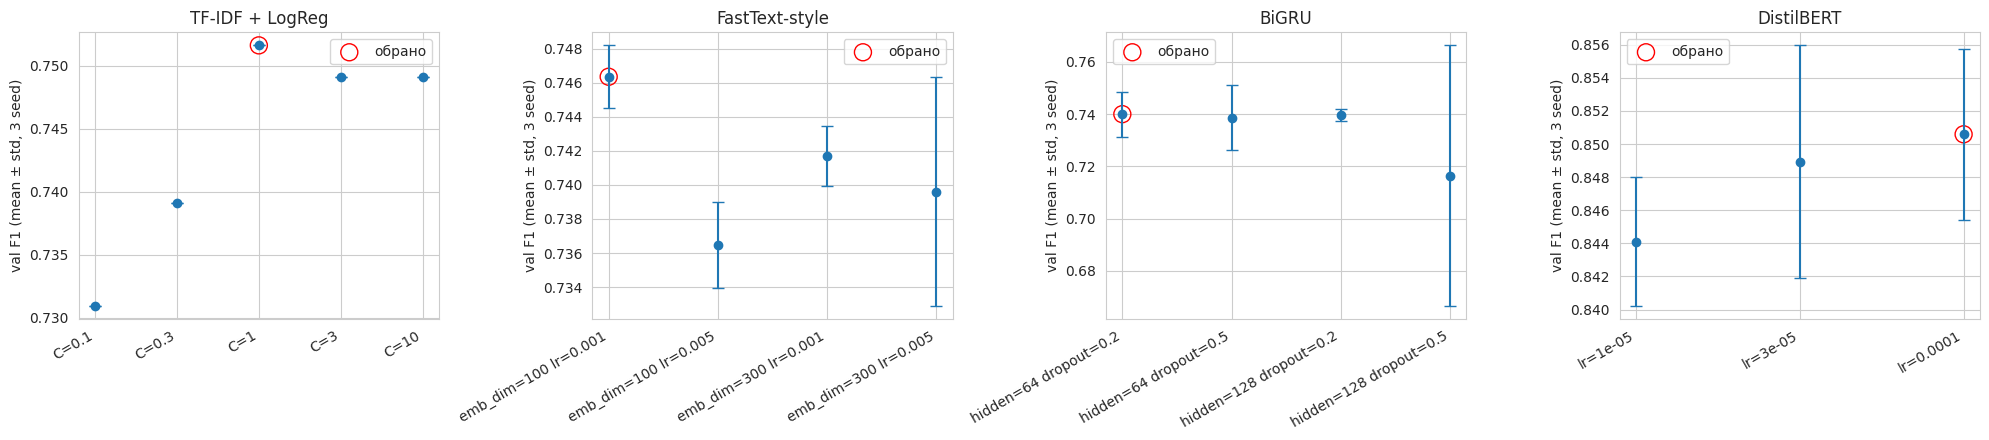

In [19]:
df = runs_df()
df.to_csv(RESULTS / "all_runs.csv", index=False)

exp = (df[df.frac == 1].groupby(["model", "config"], sort=False)
       .agg(val_f1_mean=("val_f1", "mean"), val_f1_std=("val_f1", "std"),
            epochs=("epochs_run", "mean"), train_time_s=("train_time", "mean"))
       .reset_index())
exp["selected"] = exp.apply(lambda r: r.config == config_label(r.model, BEST[r.model]), axis=1)
exp.assign(model=exp.model.map(NAMES)).to_csv(RESULTS / "hyperparameter_experiments.csv", index=False)
print(exp.assign(model=exp.model.map(NAMES)).round(4).to_string(index=False))

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, m in zip(axes, MODELS):
    g = exp[exp.model == m]
    ax.errorbar(range(len(g)), g.val_f1_mean, yerr=g.val_f1_std, fmt="o", capsize=4)
    ax.scatter(np.flatnonzero(g.selected), g.val_f1_mean[g.selected], s=150, facecolors="none",
               edgecolors="red", label="обрано")
    ax.set_xticks(range(len(g)), g.config, rotation=30, ha="right")
    ax.set(title=NAMES[m], ylabel="val F1 (mean ± std, 3 seed)")
    ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "hyperparameters.png", dpi=150)
plt.show()

> **Спостереження (гіперпараметри).**
> - **TF-IDF:** найкраще `C = 1` (val F1 0.752). Сильна регуляризація (`C = 0.1`) недонавчає модель (0.731), при `C ≥ 3`
>   якість виходить на плато (0.749). Модель детермінована, тому std = 0.
> - **FastText:** важливіший параметр — learning rate: `lr = 1e-3` кращий за `5e-3` (для `emb_dim = 100` на 1 п.п.
>   при std ≈ 0.002; для 300 — лише на 0.2 п.п., у межах шуму). При `lr = 5e-3` модель перенавчається за 2–3 епохи (розділ 10).
>   Збільшення `emb_dim` зі 100 до 300 не допомагає. Обрано `emb_dim = 100, lr = 1e-3`.
> - **BiGRU:** три конфігурації практично однакові (0.740 / 0.739 / 0.740 при std 0.003–0.012), тобто вибір між ними —
>   у межах шуму. Комбінація `hidden = 128, dropout = 0.5` нестабільна (0.716 ± 0.050): для seed 1 навчання «застрягло»
>   на val F1 ≈ 0.66 і зупинилося ранньою зупинкою. Обрано `hidden = 64, dropout = 0.2`.
> - **DistilBERT:** `lr` = 1e-5 / 3e-5 / 1e-4 дають 0.844 / 0.849 / 0.851. Різниця між 3e-5 і 1e-4 (0.002) менша за std
>   між seed (0.005–0.007), тож ці значення статистично нерозрізненні. За протоколом обрано `lr = 1e-4` (найвище середнє
>   val F1). Водночас криві в розділі 10 показують, що при `lr = 1e-4` validation loss зростає вже з 1-ї епохи — це
>   найагресивніше значення, і воно найменш стабільне на test (розділ 9). Вибір не переглядаємо: це означало б
>   підбирати модель за test.

## 9. Фінальне порівняння на test

Лише обрані за validation конфігурації. Метрики — mean ± std за 3 seed; час — середній.
Бутстреп-інтервал (1000 повторних вибірок test) показує невизначеність, пов'язану з розміром test (1066 прикладів).
Парне порівняння відповідає на питання, чи різниця між моделями більша за шум test: якщо 95% CI різниці не містить 0,
різниця значуща.

In [20]:
df = runs_df()
final = df[(df.frac == 1) & is_best(df)]
COLS = ["test_acc", "test_precision", "test_recall", "test_f1", "test_ap"]
mean_std = lambda s: f"{s.mean():.4f} ± {s.std():.4f}"

table = final.groupby("model", sort=False).agg(
    **{c: (c, mean_std) for c in COLS},
    train_time_s=("train_time", "mean"), infer_time_s=("infer_time", "mean"), n_params=("n_params", "first"))

preds = {m: to_pred(best_run(m)["test_scores"]) for m in MODELS}
table[f"F1 95% CI (seed {SEEDS[0]})"] = ["[{:.3f}, {:.3f}]".format(*bootstrap_f1(y["test"], preds[m]))
                                         for m in table.index]
table.index = table.index.map(NAMES)
table.to_csv(RESULTS / "final_metrics.csv")
print(table.round(2).to_string())

print("\nПарний бутстреп: різниця test F1, 95% CI")
for a, b in [("fasttext", "tfidf"), ("bigru", "fasttext"), ("distilbert", "bigru"), ("distilbert", "tfidf")]:
    lo, hi = bootstrap_f1(y["test"], preds[a], preds[b])
    verdict = "значуща" if lo > 0 or hi < 0 else "незначуща"
    print(f"  {NAMES[a]:>15} − {NAMES[b]:<15}: [{lo:+.3f}, {hi:+.3f}]  → {verdict}")

                        test_acc   test_precision      test_recall          test_f1          test_ap  train_time_s  infer_time_s  n_params F1 95% CI (seed 1)
model                                                                                                                                                        
TF-IDF + LogReg  0.7880 ± 0.0000  0.7913 ± 0.0000  0.7824 ± 0.0000  0.7868 ± 0.0000  0.8690 ± 0.0000          0.63          0.06     24084     [0.760, 0.813]
FastText-style   0.7739 ± 0.0041  0.7772 ± 0.0047  0.7680 ± 0.0110  0.7725 ± 0.0053  0.8619 ± 0.0031          8.22          0.02    898302     [0.744, 0.802]
BiGRU            0.7402 ± 0.0016  0.7273 ± 0.0111  0.7692 ± 0.0216  0.7474 ± 0.0047  0.8228 ± 0.0068         14.29          0.06   1224322     [0.722, 0.778]
DistilBERT       0.8368 ± 0.0167  0.8393 ± 0.0127  0.8330 ± 0.0273  0.8360 ± 0.0183  0.9221 ± 0.0077         43.01          0.46  66955010     [0.790, 0.841]

Парний бутстреп: різниця test F1, 95% CI
   FastTex

> **Спостереження (фінальні метрики).**
> - **Рейтинг за test F1:** DistilBERT 0.836 ± 0.018 > TF-IDF 0.787 > FastText 0.773 ± 0.005 > BiGRU 0.747 ± 0.005.
>   Таке саме впорядкування за AP: 0.922 > 0.869 > 0.862 > 0.823.
> - **DistilBERT значуще кращий** за TF-IDF (+4.9 п.п. у середньому за seed; 95% CI різниці для seed 1: [+0.001, +0.056])
>   і за BiGRU ([+0.038, +0.095]). Бутстреп рахувався для seed 1 — найгіршого seed DistilBERT (F1 0.816 проти 0.852
>   і 0.841), тож ця оцінка консервативна.
> - **Різниці між TF-IDF, FastText і BiGRU статистично незначущі** на test з 1066 прикладів (CI містять 0), хоча тенденція
>   стабільна: моделі, що навчаються з нуля, не перевершили TF-IDF.
> - **Вартість:** DistilBERT має 67 млн параметрів (у 55–75 разів більше за BiGRU/FastText і у ~2800 разів більше
>   за TF-IDF), навчається 43 с на GPU проти 0.6 с у TF-IDF на CPU (~70×) і в ~8 разів повільніший на інференсі
>   (0.46 с проти 0.06 с на 1066 текстів).
> - Великий std DistilBERT (0.018) зумовлений здебільшого одним seed — чутливість до seed при великому `lr = 1e-4`.

## 10. Збіжність і стабільність навчання

Для кожної нейромережі — усі конфігурації сітки (seed 1): train loss (суцільна лінія), validation loss (пунктир)
і val F1 за епохами. Діагностика (лекція з оптимізації, §19): train loss падає, а validation loss зростає →
перенавчання, тут спрацьовує рання зупинка.

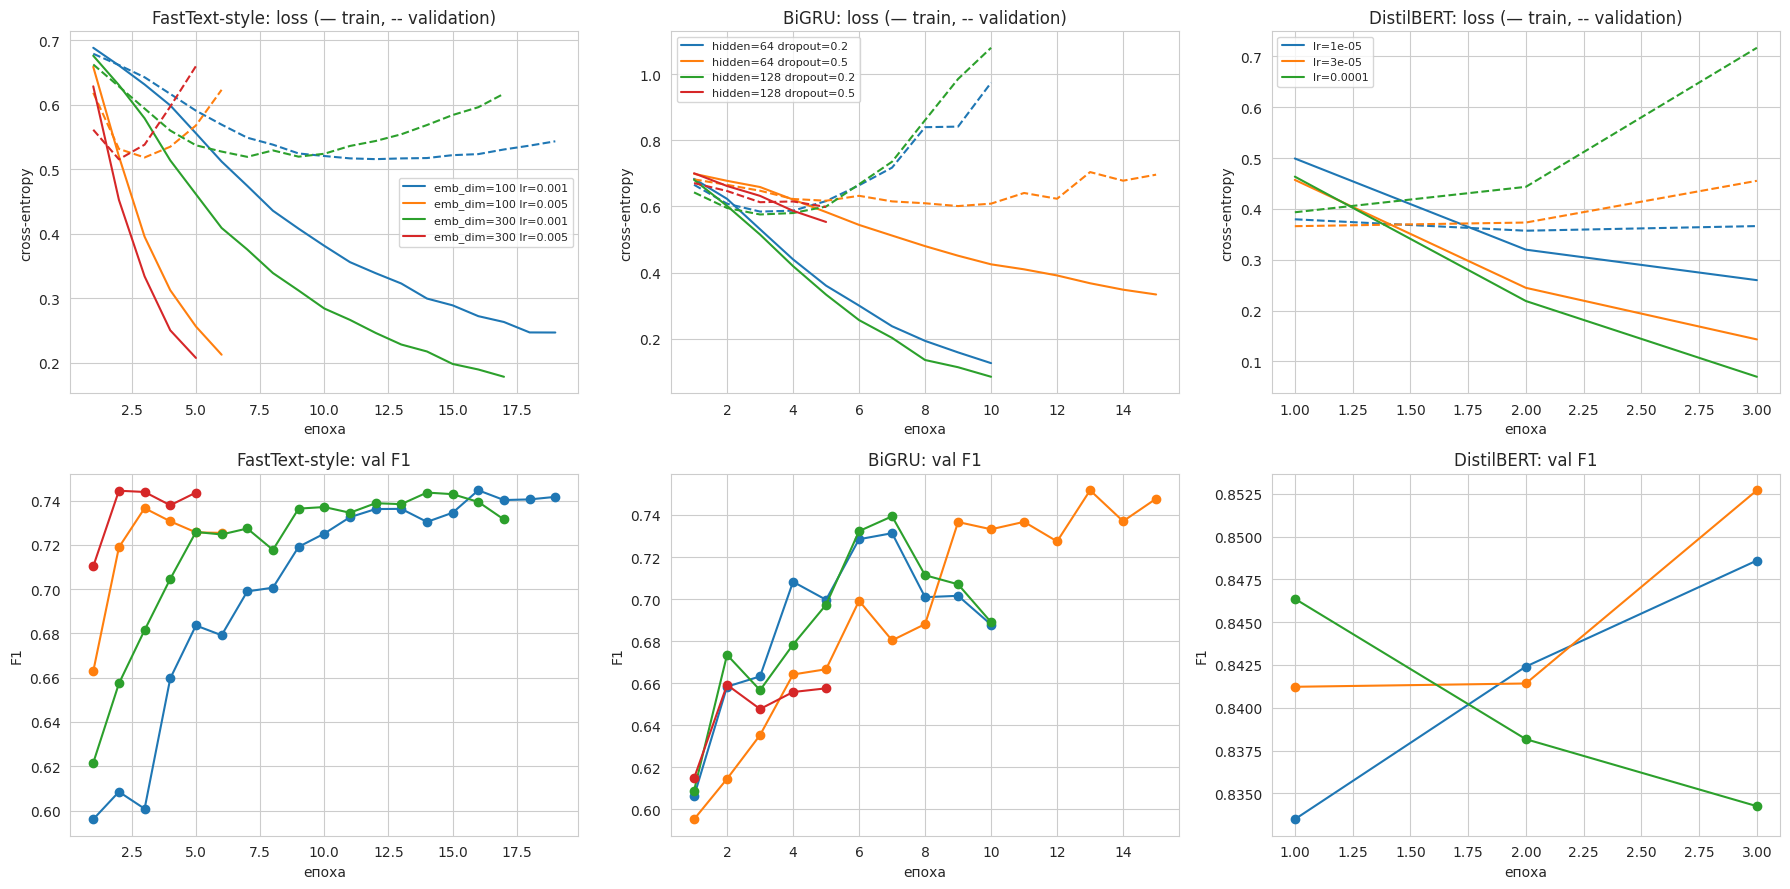

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for j, m in enumerate(["fasttext", "bigru", "distilbert"]):
    for i, r in enumerate(runs_of(m)):
        h, color = r["history"], f"C{i}"
        epochs = range(1, len(h["val_loss"]) + 1)
        axes[0, j].plot(epochs, h["train_loss"], "-", color=color, label=r["config"])
        axes[0, j].plot(epochs, h["val_loss"], "--", color=color)
        axes[1, j].plot(epochs, h["val_f1"], "o-", color=color, label=r["config"])
    axes[0, j].set(title=f"{NAMES[m]}: loss (— train, -- validation)", xlabel="епоха", ylabel="cross-entropy")
    axes[1, j].set(title=f"{NAMES[m]}: val F1", xlabel="епоха", ylabel="F1")
    axes[0, j].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "convergence.png", dpi=150)
plt.show()

Норма градієнта BiGRU (до обрізання) та частка кроків, на яких спрацював clipping. Clipping — «запобіжник» від
вибуху градієнта, а не ліки від його затухання (лекція RNN, §8).

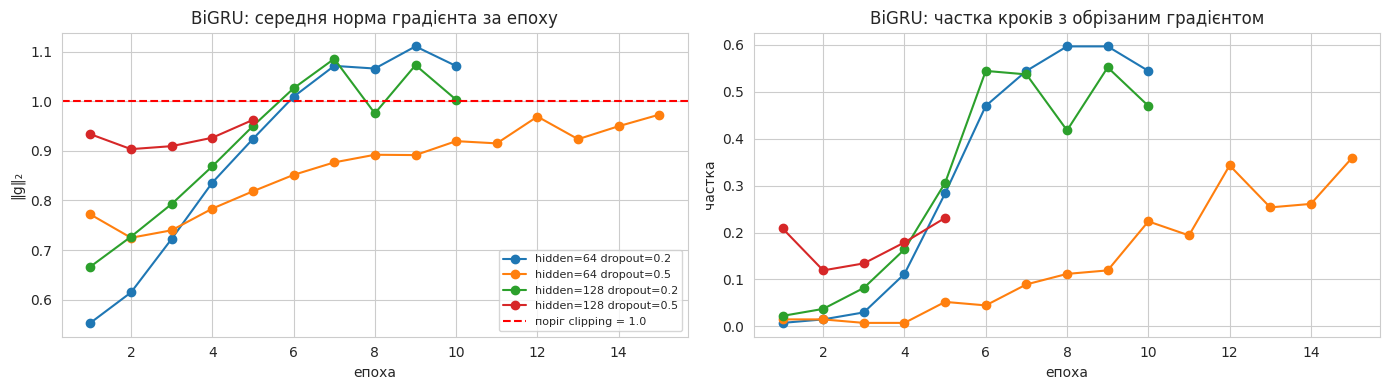

Стабільність обраних конфігурацій за 3 seed:
                  best_epoch_mean  val_f1_std  test_f1_std
model                                                    
TF-IDF + LogReg           0.0000      0.0000       0.0000
FastText-style           19.6667      0.0018       0.0053
BiGRU                    10.6667      0.0086       0.0047
DistilBERT                3.0000      0.0052       0.0183


In [23]:
clip = CFG["bigru"]["fixed"]["clip"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for r in runs_of("bigru"):
    epochs = range(1, len(r["history"]["grad_norm"]) + 1)
    ax[0].plot(epochs, r["history"]["grad_norm"], "o-", label=r["config"])
    ax[1].plot(epochs, r["history"]["clip_frac"], "o-", label=r["config"])
ax[0].axhline(clip, color="red", ls="--", label=f"поріг clipping = {clip}")
ax[0].set(title="BiGRU: середня норма градієнта за епоху", xlabel="епоха", ylabel="‖g‖₂")
ax[1].set(title="BiGRU: частка кроків з обрізаним градієнтом", xlabel="епоха", ylabel="частка")
ax[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "bigru_grad_norm.png", dpi=150)
plt.show()

stab = final.groupby("model", sort=False).agg(
    best_epoch_mean=("epochs_run", "mean"), val_f1_std=("val_f1", "std"), test_f1_std=("test_f1", "std"))
print("Стабільність обраних конфігурацій за 3 seed:\n", stab.rename(index=NAMES).round(4))

> **Спостереження (збіжність і стабільність).**
> - **Моделі з нуля демонструють класичне перенавчання:** train loss монотонно спадає, а validation loss має U-подібну форму.
>   У BiGRU мінімум val loss (≈ 0.58) досягається вже на 3–4 епосі, далі val loss зростає понад 1.0, поки train loss падає
>   до ≈ 0.1. Val F1 BiGRU досягає максимуму на 6–7 епосі й потім знижується → спрацьовує рання зупинка.
> - **Dropout стримує перенавчання:** для BiGRU з `dropout = 0.5` val loss тримається на рівні 0.6–0.7, а val F1
>   повільно зростає до 13-ї епохи.
> - **FastText** перенавчається тим швидше, чим більший lr: при `lr = 5e-3` мінімум val loss — на 2–3 епосі,
>   при `1e-3` — на 7–12-й. При `lr = 1e-3` val F1 продовжує зростати й після мінімуму val loss: модель стає надто
>   впевненою (loss ↑), але частка правильних відповідей ще покращується. Через це обрана конфігурація майже завжди
>   доходила до ліміту 20 епох — ліміт міг трохи обмежити її якість.
> - **Норма градієнта BiGRU** зростає з 0.55–0.75 до ≈ 1.1 у міру навчання. Clipping (поріг 1.0) у перших епохах майже
>   не спрацьовує (< 5% кроків), а у фазі перенавчання — на 45–60% кроків. Вибуху градієнта немає: clipping лише страхує.
> - **DistilBERT** сходиться за 1–2 епохи. При `lr = 1e-5` val loss стабільний (≈ 0.36), а val F1 ще зростає на 3-й епосі
>   (довше навчання могло б допомогти). При `lr = 1e-4` val loss зростає з першої епохи (0.39 → 0.72): модель швидко
>   стає надмірно впевненою, і для seed 1 найкращою виявляється вже 1-ша епоха (її й бере `load_best_model_at_end`).
> - **Стабільність за seed:** std test F1 — 0.005 у FastText і BiGRU, 0.018 у DistilBERT з `lr = 1e-4`.
>
> _Примітка: стовпець `best_epoch_mean` у таблиці вище насправді показує середню **кількість пройдених епох**
> (разом з епохами очікування ранньої зупинки), а не номер найкращої епохи: 19.7 у FastText (ліміт — 20),
> 10.7 у BiGRU (ліміт — 15), 3 у DistilBERT._

## 11. PR-криві та матриці помилок (test, обрана конфігурація, seed 1)

PR-крива показує компроміс precision–recall за всіх порогів; точкою позначено робочий поріг $\tau = 0.5$.
Average precision (AP) — площа під PR-кривою.

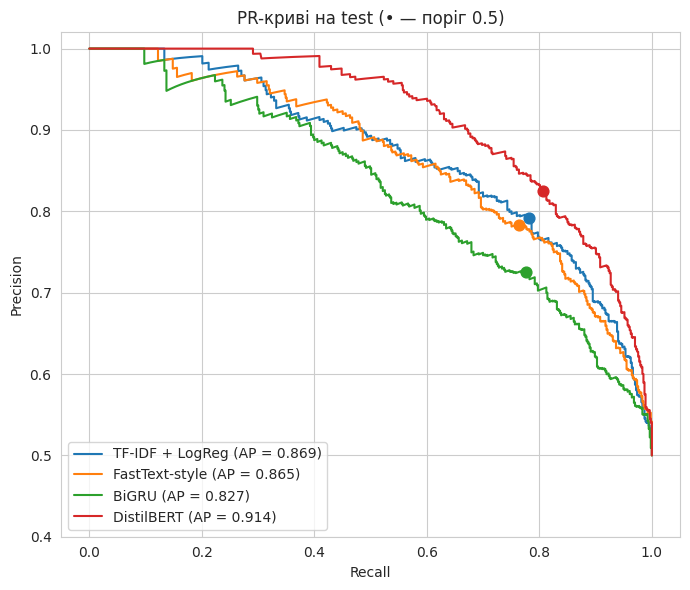

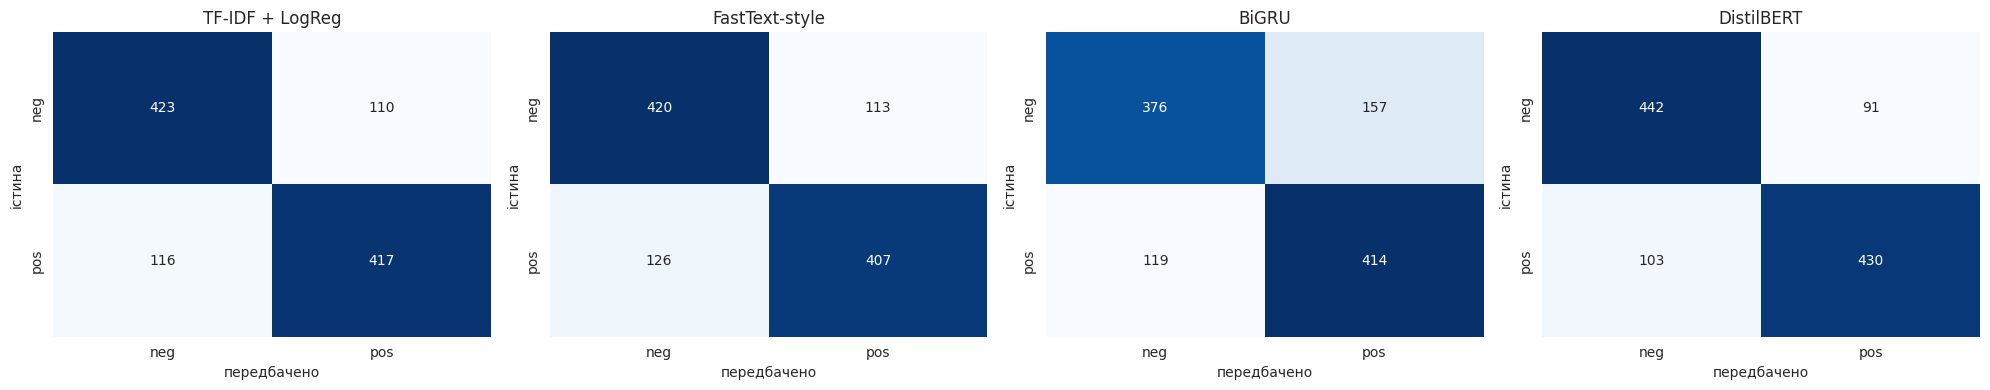

In [24]:
fig, ax = plt.subplots(figsize=(7, 6))
for m in MODELS:
    scores = best_run(m)["test_scores"]
    prec, rec, _ = precision_recall_curve(y["test"], scores)
    line, = ax.plot(rec, prec, label=f"{NAMES[m]} (AP = {average_precision_score(y['test'], scores):.3f})")
    p, r, _, _ = precision_recall_fscore_support(y["test"], to_pred(scores), average="binary")
    ax.scatter(r, p, color=line.get_color(), s=60, zorder=3)
ax.set(xlabel="Recall", ylabel="Precision", title="PR-криві на test (• — поріг 0.5)", ylim=(0.4, 1.02))
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "pr_curves.png", dpi=150)
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, m in zip(axes, MODELS):
    sns.heatmap(confusion_matrix(y["test"], preds[m]), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["neg", "pos"], yticklabels=["neg", "pos"])
    ax.set(title=NAMES[m], xlabel="передбачено", ylabel="істина")
plt.tight_layout()
plt.savefig(FIG_DIR / "confusion_matrices.png", dpi=150)
plt.show()

## 12. Вибіркова ефективність

Кожна модель з обраною конфігурацією навчається на 5%, 10%, 25%, 50% train (× 3 seed; підвибірка однакова для всіх
моделей). Точка 100% береться з основних прогонів. Validation і test — повні.

In [25]:
RUN_FNS = {"tfidf": run_tfidf, "fasttext": partial(run_torch, "fasttext"),
           "bigru": partial(run_torch, "bigru"), "distilbert": run_bert}
for m, run_fn in RUN_FNS.items():
    runs[:] = [r for r in runs if not (r["model"] == m and r["frac"] < 1)]
    runs.extend(run_fn(BEST[m], seed, frac) for frac in FRACS if frac < 1 for seed in SEEDS)

tfidf_C=1_s1_f0.05                                           val F1 = 0.6033   (0.0 s)
tfidf_C=1_s2_f0.05                                           val F1 = 0.5906   (0.0 s)
tfidf_C=1_s42_f0.05                                          val F1 = 0.6135   (0.0 s)
tfidf_C=1_s1_f0.1                                            val F1 = 0.6132   (0.1 s)
tfidf_C=1_s2_f0.1                                            val F1 = 0.6547   (0.1 s)
tfidf_C=1_s42_f0.1                                           val F1 = 0.6630   (0.1 s)
tfidf_C=1_s1_f0.25                                           val F1 = 0.7140   (0.1 s)
tfidf_C=1_s2_f0.25                                           val F1 = 0.7161   (0.1 s)
tfidf_C=1_s42_f0.25                                          val F1 = 0.7186   (0.1 s)
tfidf_C=1_s1_f0.5                                            val F1 = 0.7333   (0.6 s)
tfidf_C=1_s2_f0.5                                            val F1 = 0.7271   (1.2 s)
tfidf_C=1_s42_f0.5                         

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

{'loss': '0.6581', 'grad_norm': '4.771', 'learning_rate': '7.632e-05', 'epoch': '1'}
{'eval_loss': '0.5776', 'eval_accuracy': '0.7008', 'eval_f1': '0.7544', 'eval_runtime': '0.4357', 'eval_samples_per_second': '2447', 'eval_steps_per_second': '39.02', 'epoch': '1'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.416', 'grad_norm': '11.33', 'learning_rate': '3.947e-05', 'epoch': '2'}
{'eval_loss': '0.4574', 'eval_accuracy': '0.7889', 'eval_f1': '0.7891', 'eval_runtime': '0.4446', 'eval_samples_per_second': '2398', 'eval_steps_per_second': '38.24', 'epoch': '2'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (87 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.06522', 'grad_norm': '0.05354', 'learning_rate': '2.762e-07', 'epoch': '3'}
{'eval_loss': '0.6116', 'eval_accuracy': '0.849', 'eval_f1': '0.8511', 'eval_runtime': '0.4408', 'eval_samples_per_second': '2418', 'eval_steps_per_second': '38.56', 'epoch': '3'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'train_runtime': '22.29', 'train_samples_per_second': '574', 'train_steps_per_second': '18.04', 'train_loss': '0.2603', 'epoch': '3'}
distilbert_lr=0.0001_s42_f0.5                                val F1 = 0.8511   (22.7 s)


model    TF-IDF + LogReg  FastText-style   BiGRU  DistilBERT
n_train                                                     
426               0.6176          0.5635  0.5699      0.7831
853               0.6468          0.5555  0.5921      0.8089
2132              0.7274          0.6827  0.6474      0.8129
4265              0.7619          0.7375  0.6804      0.8301
8530              0.7868          0.7725  0.7474      0.8360


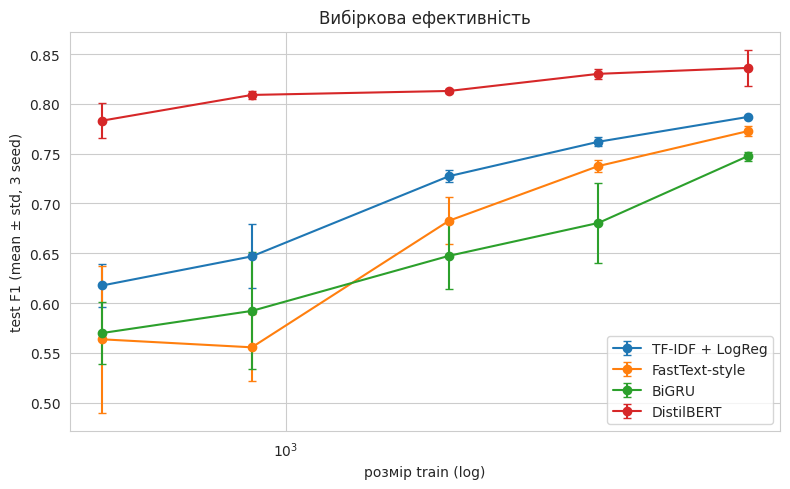

In [28]:
df = runs_df()
df.to_csv(RESULTS / "all_runs.csv", index=False)
se = (df[is_best(df)].groupby(["model", "frac"])
      .agg(n_train=("n_train", "first"), f1_mean=("test_f1", "mean"), f1_std=("test_f1", "std"))
      .reset_index())
se.to_csv(RESULTS / "sample_efficiency.csv", index=False)
print(se.pivot(index="n_train", columns="model", values="f1_mean")[MODELS].rename(columns=NAMES).round(4))

plt.figure(figsize=(8, 5))
for m in MODELS:
    g = se[se.model == m]
    plt.errorbar(g.n_train, g.f1_mean, yerr=g.f1_std, marker="o", capsize=3, label=NAMES[m])
plt.xscale("log")
plt.xlabel("розмір train (log)")
plt.ylabel("test F1 (mean ± std, 3 seed)")
plt.title("Вибіркова ефективність")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "sample_efficiency.png", dpi=150)
plt.show()

> **Спостереження (вибіркова ефективність).**
> - **DistilBERT на 426 прикладах (5% train) досягає F1 0.783 — майже як TF-IDF на всіх 8530 (0.787)**, тобто йому
>   потрібно приблизно у 20 разів менше розмічених даних. Перехід від 5% до 100% додає DistilBERT лише +5 п.п.:
>   основне знання про мову модель отримала під час передтренування.
> - Моделі, що навчаються з нуля, сильно залежать від обсягу даних: від 5% до 100% F1 зростає на 17–21 п.п.
>   (TF-IDF 0.618 → 0.787, FastText 0.564 → 0.773, BiGRU 0.570 → 0.747), і криві не вийшли на плато — більше даних
>   ще допомогло б.
> - На малих вибірках нейромережі з нуля нестабільні (std до 0.07 у FastText на 5%) і поступаються TF-IDF за будь-якого
>   розміру train; FastText майже наздоганяє TF-IDF лише на повному train.
> - BiGRU — найменш вибірково ефективна модель на ≥ 25% даних: рекурентній мережі з 1.2 млн параметрів потрібно найбільше
>   даних, щоб навчитися корисних представлень.

## 13. Аналіз помилок

Замість кількох вибраних вручну прикладів рахуємо **частку помилок у групах** test-прикладів (обрана конфігурація,
seed 1). Групи визначаються словниками ключових слів, тож це наближення:
- **заперечення** (not, no, never, n't, without, …) — класичний виклик для моделей «мішка слів» (лекція RNN, §2.2:
  «не дуже хороший фільм»);
- **контраст** (but, however, although, despite, …) — змішана тональність, де вирішальною є одна частина речення;
- **довжина** — коротші/довші за медіану.

Потім дивимося, наскільки збігаються помилки різних моделей, і розглядаємо випадкову вибірку (seed 0) прикладів,
складних для всіх моделей.

In [30]:
texts = X["test"]
NEG = re.compile(r"\b(?:not|no|never|nothing|none|nobody|nor|neither|without|hardly)\b|n't\b")
CONTRAST = re.compile(r"\b(?:but|however|although|though|despite|nevertheless)\b")
has_neg = np.array([bool(NEG.search(t)) for t in texts])
has_contrast = np.array([bool(CONTRAST.search(t)) for t in texts])
n_words = np.array([len(t.split()) for t in texts])
short = n_words <= np.median(n_words)

groups = {"усі": np.ones(len(texts), bool),
          "із запереченням": has_neg, "без заперечення": ~has_neg,
          "з контрастом": has_contrast, "без контрасту": ~has_contrast,
          f"короткі (≤ {np.median(n_words):.0f} слів)": short, "довгі": ~short}
wrong = {m: preds[m] != y["test"] for m in MODELS}

err = pd.DataFrame({NAMES[m]: {g: wrong[m][mask].mean() for g, mask in groups.items()} for m in MODELS})
err.insert(0, "n", {g: int(mask.sum()) for g, mask in groups.items()})
err.to_csv(RESULTS / "error_rates_by_group.csv")
print("Частка помилок у групах test:\n", err.round(3))

both = pd.DataFrame([[int((wrong[a] & wrong[b]).sum()) for b in MODELS] for a in MODELS],
                    index=[NAMES[m] for m in MODELS], columns=[NAMES[m] for m in MODELS])
print("\nКількість спільних помилок (діагональ — усі помилки моделі):\n", both)
all_wrong = np.logical_and.reduce([wrong[m] for m in MODELS])
print(f"\nПомиляються всі 4 моделі: {all_wrong.sum()} з {len(texts)}")

Частка помилок у групах test:
                         n  TF-IDF + LogReg  FastText-style  BiGRU  DistilBERT
усі                  1066            0.212           0.224  0.259       0.182
із запереченням       256            0.215           0.234  0.293       0.227
без заперечення       810            0.211           0.221  0.248       0.168
з контрастом          199            0.276           0.302  0.332       0.271
без контрасту         867            0.197           0.206  0.242       0.161
короткі (≤ 20 слів)   542            0.201           0.221  0.227       0.155
довгі                 524            0.223           0.227  0.292       0.210

Кількість спільних помилок (діагональ — усі помилки моделі):
                  TF-IDF + LogReg  FastText-style  BiGRU  DistilBERT
TF-IDF + LogReg              226             159    150         103
FastText-style               159             239    155          98
BiGRU                        150             155    276         107
DistilBERT

In [31]:
def show(idx, title, k=10):
    print(f"\n{title} — {len(idx)} прикладів, випадкові {min(k, len(idx))} (seed 0):")
    for i in np.random.RandomState(0).choice(idx, min(k, len(idx)), replace=False):
        tags = [t for t, flag in [("NEG", has_neg[i]), ("CONTRAST", has_contrast[i])] if flag]
        print(f"  true={y['test'][i]}  p(pos)={best_run('distilbert')['test_scores'][i]:.2f}  "
              f"{','.join(tags) or '-':<12} | {texts[i]}")


show(np.flatnonzero(all_wrong), "Складні для всіх моделей")
show(np.flatnonzero(wrong["distilbert"] & ~wrong["tfidf"]), "DistilBERT помиляється, TF-IDF — ні", k=5)
show(np.flatnonzero(~wrong["distilbert"] & wrong["tfidf"]), "TF-IDF помиляється, DistilBERT — ні", k=5)


Складні для всіх моделей — 64 прикладів, випадкові 10 (seed 0):
  true=0  p(pos)=0.95  -            | [lee] treats his audience the same way that jim brown treats his women -- as dumb , credulous , unassuming , subordinate subjects . and lee seems just as expectant of an adoring , wide-smiling reception .
  true=1  p(pos)=0.07  CONTRAST     | the script's snazzy dialogue establishes a realistic atmosphere that involves us in the unfolding crisis , but the lazy plotting ensures that little of our emotional investment pays off .
  true=0  p(pos)=0.77  CONTRAST     | behan's memoir is great material for a film -- rowdy , brawny and lyrical in the best irish sense -- but sheridan has settled for a lugubrious romance .
  true=0  p(pos)=0.67  NEG          | . . . a ho-hum affair , always watchable yet hardly memorable .
  true=0  p(pos)=0.97  -            | this is surely one of the most frantic , virulent and foul-natured christmas season pics ever delivered by a hollywood studio .
  true=

> **Спостереження (помилки).**
> - **Найскладніші — речення з контрастом** (but, however, although…): частка помилок зростає на 7–11 п.п. для всіх
>   моделей (наприклад, DistilBERT: 27.1% проти 16.1%). Загальна оцінка залежить від того, яка частина речення
>   «важить» більше, — це змішана тональність.
> - **Заперечення не шкодить TF-IDF** (21.5% проти 21.1%): біграми на кшталт «not good» прямо кодують заперечення.
>   Нейромережам воно шкодить: BiGRU +4.5 п.п., DistilBERT +5.9 п.п. Очікування, що BiGRU завдяки порядку слів краще
>   обробить заперечення, ніж FastText, **не підтвердилося** (29.3% проти 23.4%): на 8.5 тис. речень і з ≈ 9% `<unk>`
>   у test рекурентній мережі бракує даних, щоб вивчити композиційне значення заперечення.
> - **Довгі речення** найбільше шкодять BiGRU (+6.5 п.п.: 29.2% проти 22.7%) — узгоджується з тим, що рекурентній мережі
>   важче переносити інформацію через довгу послідовність (лекція RNN, §7). Для FastText довжина майже не важлива (+0.6 п.п.).
> - **Помилки моделей різняться:** TF-IDF і FastText мають 159 спільних помилок (з 226 і 239) — обидві по суті «мішки слів».
>   DistilBERT ділить із кожною моделлю лише ≈ 100 помилок; є 91 приклад, де DistilBERT помиляється, а TF-IDF — ні,
>   і 123 — навпаки. Моделі взаємодоповнюють одна одну, тож ансамбль міг би дати приріст.
> - **64 приклади (6%) складні для всіх чотирьох моделей.** У випадковій вибірці з них: іронія без явних оцінних слів
>   («[lee] treats his audience the same way that jim brown treats his women …»), змішані відгуки («the beautiful, unusual
>   music is this film's chief draw, but its dreaminess may lull you to sleep») і, ймовірно, **шум у мітках**: речення
>   «… the lazy plotting ensures that little of our emotional investment pays off» та «… to cover up the yawning chasm
>   where the plot should be» мають мітку positive. Мітки успадковано від оцінки всієї рецензії (fresh / rotten),
>   а не конкретного речення.

## 14. Висновки

1. **TF-IDF baseline сильний:** F1 0.787 (AP 0.869) за 0.6 с навчання на CPU. На цьому датасеті жодна модель,
   що навчалася з нуля, його не перевершила.
2. **Порядок слів сам по собі не допоміг:** BiGRU (F1 0.747) не кращий за FastText-усереднення (0.773). Різниця
   незначуща (95% CI [−0.050, +0.001]), але тенденція не на користь BiGRU, і він гірше справляється із запереченням
   та довгими реченнями. На ~8.5 тис. коротких речень рекурентній моделі з нуля бракує даних.
3. **DistilBERT — найкраща модель:** F1 0.836 ± 0.018, AP 0.922, значуще кращий за TF-IDF (+4.9 п.п.) і BiGRU (+8.9 п.п.).
   Ціна — 67 млн параметрів, ~70× довше навчання і ~8× повільніший інференс порівняно з TF-IDF.
4. **Вибіркова ефективність — головна перевага передтренування:** DistilBERT на 5% даних (426 прикладів) майже досягає
   TF-IDF на 100%, тоді як моделі з нуля при зменшенні даних втрачають 17–21 п.п.
5. **Складні випадки для всіх моделей** — змішана тональність (контраст), іронія, відсутність явних оцінних слів
   і, ймовірно, шум у мітках; 6% test-прикладів помилкові для всіх чотирьох моделей.
6. **Компроміс якість / вартість:** якщо важлива якість — DistilBERT; якщо потрібні мінімальні ресурси, інтерпретованість
   і миттєве навчання — TF-IDF + LogReg (−5 п.п. F1). FastText і BiGRU без передтренованих embeddings на такому обсязі
   даних не мають переваг над TF-IDF.

### Обмеження
- Один домен (короткі англомовні рецензії на фільми); перенесення на інші домени не перевірялося.
- Test містить 1066 прикладів → невизначеність F1 близько ±2.5 п.п. (бутстреп CI), тому різниці між TF-IDF, FastText
  і BiGRU незначущі.
- Validation використовувався і для вибору гіперпараметрів, і для ранньої зупинки → val F1 оптимістичний
  (у DistilBERT 0.851 на validation проти 0.836 на test).
- Мітки отримано автоматично з позначок рецензій (fresh / rotten), тому є шум, особливо для змішаних відгуків;
  трапляються тексти не англійською.
- BiGRU і FastText навчаються з нуля, ≈ 9% слів test не входять до словника; передтреновані embeddings (GloVe,
  word2vec) могли б суттєво їх покращити.
- Сітки гіперпараметрів малі, а ліміти епох фіксовані: FastText майже завжди доходив до 20 епох, DistilBERT
  з `lr = 1e-5` ще покращувався на 3-й епосі.
- Критерій вибору (середній val F1) обрав для DistilBERT найагресивніший `lr = 1e-4`, найменш стабільний на test;
  за val loss перевагу мав би `lr = 1e-5`. Варто розглядати комбінований критерій.
- Бутстреп-порівняння виконано для одного seed (seed 1).
- Час виміряно на різному обладнанні (TF-IDF — CPU, нейромережі — одна GPU T4), тому для TF-IDF порівнюємо
  порядки величин, а не точні значення.
- Групи помилок (заперечення, контраст) визначено словниками ключових слів — це лише наближення до мовних явищ.

## Джерела

- Pang B., Lee L. *Seeing stars: Exploiting class relationships for sentiment categorization with respect to rating scales.* ACL, 2005 — датасет Rotten Tomatoes.
- Sanh V., Debut L., Chaumond J., Wolf T. *DistilBERT, a distilled version of BERT: smaller, faster, cheaper and lighter.* 2019.
- Devlin J. et al. *BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding.* NAACL, 2019.
- Cho K. et al. *Learning Phrase Representations using RNN Encoder–Decoder for Statistical Machine Translation.* EMNLP, 2014 — GRU.
- Schuster M., Paliwal K. *Bidirectional Recurrent Neural Networks.* IEEE Trans. Signal Processing, 1997.
- Joulin A., Grave E., Bojanowski P., Mikolov T. *Bag of Tricks for Efficient Text Classification.* EACL, 2017 — fastText.
- Loshchilov I., Hutter F. *Decoupled Weight Decay Regularization.* ICLR, 2019 — AdamW.
- Pascanu R., Mikolov T., Bengio Y. *On the Difficulty of Training Recurrent Neural Networks.* ICML, 2013 — gradient clipping.
- Saito T., Rehmsmeier M. *The Precision-Recall Plot Is More Informative than the ROC Plot…* PLOS ONE, 2015.
- Wolf T. et al. *Transformers: State-of-the-Art Natural Language Processing.* EMNLP (Demos), 2020; Paszke A. et al. *PyTorch*, NeurIPS, 2019; Pedregosa F. et al. *Scikit-learn*, JMLR, 2011.
- Матеріали курсу «Нейронні мережі»: «Підготовка навчальної та тестової вибірки», «Методи оптимізації у нейронних мережах», «Рекурентні нейронні мережі».